In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=FutureWarning)

current_path = Path.cwd()

project_root = next(
    (
        path
        for path in [current_path, *current_path.parents]
        if (path / "src" / "config.py").exists()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate the project root containing src/config.py."
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_loader import load_raw_data
from src.features.metric_definitions import add_metric_features
from src.features.player_level import (
    build_player_season_batting,
    build_player_season_bowling,
    build_player_season_phase_batting,
    build_player_season_phase_bowling,
)

print(f"Project root: {project_root}")

Project root: /Users/soham/MyDocs/Projects/Cricket Analysis/Hackathon - DPL 2026/CodeFiles/Hackathon_DPL2026


In [2]:
df = load_raw_data()
df_features = add_metric_features(df)

player_season_batting = build_player_season_batting(df_features)
player_season_bowling = build_player_season_bowling(df_features)

player_season_phase_batting = build_player_season_phase_batting(df_features)
player_season_phase_bowling = build_player_season_phase_bowling(df_features)

player_datasets = {
    "Player-season batting": player_season_batting,
    "Player-season bowling": player_season_bowling,
    "Player-season-phase batting": player_season_phase_batting,
    "Player-season-phase bowling": player_season_phase_bowling,
}

for name, dataset in player_datasets.items():
    print(f"{name}: {dataset.shape}")

Player-season batting: (347, 12)
Player-season bowling: (273, 18)
Player-season-phase batting: (733, 13)
Player-season-phase bowling: (672, 19)


In [3]:
print("PLAYER-SEASON BATTING")
display(
    player_season_batting.head()
)
print(player_season_batting.columns.tolist())

print("\nPLAYER-SEASON BOWLING")
display(
    player_season_bowling.head()
)
print(player_season_bowling.columns.tolist())

print("\nPLAYER-SEASON-PHASE BATTING")
display(
    player_season_phase_batting.head()
)
print(player_season_phase_batting.columns.tolist())

print("\nPLAYER-SEASON-PHASE BOWLING")
display(
    player_season_phase_bowling.head()
)
print(player_season_phase_bowling.columns.tolist())

PLAYER-SEASON BATTING


,p_bat,year,batter_name,runs,balls_faced,dot_balls,boundary_balls,boundary_runs,strike_rate,dot_ball_pct,boundary_ball_pct,boundary_run_pct
0,8917,2023,Moeen Ali,124,91,37,18,84,136.263736,40.659341,19.780220,67.741935
1,8917,2024,Moeen Ali,128,98,34,15,76,130.612245,34.693878,15.306122,59.375000
2,25913,2024,Mohammad Nabi,35,31,13,4,20,112.903226,41.935484,12.903226,57.142857
3,26421,2023,Ravichandran Ashwin,67,51,19,8,38,131.372549,37.254902,15.686275,56.716418
4,26421,2024,Ravichandran Ashwin,86,74,27,9,44,116.216216,36.486486,12.162162,51.162791


['p_bat', 'year', 'batter_name', 'runs', 'balls_faced', 'dot_balls', 'boundary_balls', 'boundary_runs', 'strike_rate', 'dot_ball_pct', 'boundary_ball_pct', 'boundary_run_pct']

PLAYER-SEASON BOWLING


,p_bowl,year,bowler_name,runs_conceded,legal_balls,dot_balls,wickets,boundary_balls,boundary_runs_conceded,wides_conceded,noball_extras_conceded,wide_noball_extras_conceded,overs_bowled,economy_rate,bowling_dot_pct,wickets_per_100_balls,boundary_balls_per_100_legal_balls,extras_per_20_overs
0,8917,2023,Moeen Ali,195,156,54,9,20,104,1,0,1,26.000000,7.500000,34.615385,5.769231,12.820513,0.769231
1,8917,2024,Moeen Ali,71,48,12,2,6,32,1,0,1,8.000000,8.875000,25.000000,4.166667,12.500000,2.500000
2,25913,2024,Mohammad Nabi,109,74,18,2,12,64,0,0,0,12.333333,8.837838,24.324324,2.702703,16.216216,0.000000
3,26421,2023,Ravichandran Ashwin,368,294,88,14,34,164,16,0,16,49.000000,7.510204,29.931973,4.761905,11.564626,6.530612
4,26421,2024,Ravichandran Ashwin,467,330,87,9,43,210,28,0,28,55.000000,8.490909,26.363636,2.727273,13.030303,10.181818


['p_bowl', 'year', 'bowler_name', 'runs_conceded', 'legal_balls', 'dot_balls', 'wickets', 'boundary_balls', 'boundary_runs_conceded', 'wides_conceded', 'noball_extras_conceded', 'wide_noball_extras_conceded', 'overs_bowled', 'economy_rate', 'bowling_dot_pct', 'wickets_per_100_balls', 'boundary_balls_per_100_legal_balls', 'extras_per_20_overs']

PLAYER-SEASON-PHASE BATTING


,p_bat,year,match_phase,batter_name,runs,balls_faced,dot_balls,boundary_balls,boundary_runs,strike_rate,dot_ball_pct,boundary_ball_pct,boundary_run_pct
0,8917,2023,Death,Moeen Ali,39,24,7,5,26,162.500000,29.166667,20.833333,66.666667
1,8917,2023,Middle,Moeen Ali,62,50,19,8,36,124.000000,38.000000,16.000000,58.064516
2,8917,2023,Powerplay,Moeen Ali,23,17,11,5,22,135.294118,64.705882,29.411765,95.652174
3,8917,2024,Death,Moeen Ali,38,19,5,5,28,200.000000,26.315789,26.315789,73.684211
4,8917,2024,Middle,Moeen Ali,72,67,25,7,36,107.462687,37.313433,10.447761,50.000000


['p_bat', 'year', 'match_phase', 'batter_name', 'runs', 'balls_faced', 'dot_balls', 'boundary_balls', 'boundary_runs', 'strike_rate', 'dot_ball_pct', 'boundary_ball_pct', 'boundary_run_pct']

PLAYER-SEASON-PHASE BOWLING


,p_bowl,year,match_phase,bowler_name,runs_conceded,legal_balls,dot_balls,wickets,boundary_balls,boundary_runs_conceded,wides_conceded,noball_extras_conceded,wide_noball_extras_conceded,overs_bowled,economy_rate,bowling_dot_pct,wickets_per_100_balls,boundary_balls_per_100_legal_balls,extras_per_20_overs
0,8917,2023,Death,Moeen Ali,3,6,3,1,0,0,0,0,0,1.0,3.000000,50.000000,16.666667,0.000000,0.000000
1,8917,2023,Middle,Moeen Ali,182,138,45,6,20,104,1,0,1,23.0,7.913043,32.608696,4.347826,14.492754,0.869565
2,8917,2023,Powerplay,Moeen Ali,10,12,6,2,0,0,0,0,0,2.0,5.000000,50.000000,16.666667,0.000000,0.000000
3,8917,2024,Death,Moeen Ali,19,12,4,1,2,12,0,0,0,2.0,9.500000,33.333333,8.333333,16.666667,0.000000
4,8917,2024,Middle,Moeen Ali,52,36,8,1,4,20,1,0,1,6.0,8.666667,22.222222,2.777778,11.111111,3.333333


['p_bowl', 'year', 'match_phase', 'bowler_name', 'runs_conceded', 'legal_balls', 'dot_balls', 'wickets', 'boundary_balls', 'boundary_runs_conceded', 'wides_conceded', 'noball_extras_conceded', 'wide_noball_extras_conceded', 'overs_bowled', 'economy_rate', 'bowling_dot_pct', 'wickets_per_100_balls', 'boundary_balls_per_100_legal_balls', 'extras_per_20_overs']


In [4]:
# Minimum workload thresholds
MIN_BATTING_BALLS = 60
MIN_PHASE_BATTING_BALLS = 12

# Core season-level batting metrics
batting_base = player_season_batting.loc[
    player_season_batting["balls_faced"].ge(MIN_BATTING_BALLS)
].copy()

# Phase-level batting metrics
batting_phase_features = (
    player_season_phase_batting
    .pivot(
        index=["p_bat", "year", "batter_name"],
        columns="match_phase",
        values="strike_rate",
    )
    .rename(
        columns={
            "Powerplay": "powerplay_strike_rate",
            "Middle": "middle_strike_rate",
            "Death": "death_strike_rate",
        }
    )
    .reset_index()
)

# Independently calculate phase workload
batting_phase_balls = (
    player_season_phase_batting
    .pivot(
        index=["p_bat", "year", "batter_name"],
        columns="match_phase",
        values="balls_faced",
    )
    .rename(
        columns={
            "Powerplay": "powerplay_balls",
            "Middle": "middle_balls",
            "Death": "death_balls",
        }
    )
    .reset_index()
)

# Combine the core and phase-level metrics
batting_features = batting_base.merge(
    batting_phase_features,
    on=["p_bat", "year", "batter_name"],
    how="left",
    validate="one_to_one",
)

batting_features = batting_features.merge(
    batting_phase_balls,
    on=["p_bat", "year", "batter_name"],
    how="left",
    validate="one_to_one",
)

# Keep only records with sufficient observations in every phase
batting_features = batting_features.loc[
    batting_features["powerplay_balls"].ge(MIN_PHASE_BATTING_BALLS)
    & batting_features["middle_balls"].ge(MIN_PHASE_BATTING_BALLS)
    & batting_features["death_balls"].ge(MIN_PHASE_BATTING_BALLS)
].copy()

batting_cluster_columns = [
    "strike_rate",
    "dot_ball_pct",
    "boundary_ball_pct",
    "powerplay_strike_rate",
    "middle_strike_rate",
    "death_strike_rate",
]

print("Eligible player-season batting records:", len(batting_features))
print("Unique players:", batting_features["p_bat"].nunique())
print("Seasons represented:", sorted(batting_features["year"].unique()))

display(
    batting_features[
        ["batter_name", "year", "runs", "balls_faced"] + batting_cluster_columns
    ]
    .head(10)
)

Eligible player-season batting records: 67
Unique players: 51
Seasons represented: [np.int64(2023), np.int64(2024)]


,batter_name,year,runs,balls_faced,strike_rate,dot_ball_pct,boundary_ball_pct,powerplay_strike_rate,middle_strike_rate,death_strike_rate
0,Moeen Ali,2023,124,91,136.263736,40.659341,19.780220,135.294118,124.000000,162.500000
1,Moeen Ali,2024,128,98,130.612245,34.693878,15.306122,150.000000,107.462687,200.000000
4,Shikhar Dhawan,2023,373,261,142.911877,41.379310,23.371648,137.068966,132.673267,181.818182
10,Rohit Sharma,2024,417,278,150.000000,43.525180,24.460432,151.977401,137.931034,200.000000
11,Faf du Plessis,2023,730,475,153.684211,28.000000,20.210526,168.544601,135.087719,185.294118
13,David Warner,2023,516,392,131.632653,40.051020,20.153061,145.853659,117.834395,106.666667
15,Sunil Narine,2024,488,270,180.740741,40.370370,30.740741,170.303030,190.322581,250.000000
18,Virat Kohli,2023,639,457,139.824945,28.446389,17.724289,136.818182,134.010152,185.000000
19,Virat Kohli,2024,741,479,154.697286,30.897704,20.876827,161.471861,136.868687,194.000000
27,Manish Pandey,2023,160,146,109.589041,37.671233,12.328767,105.714286,113.265306,92.307692


In [5]:
print("Batting feature dataset shape:", batting_features.shape)

print("\nMissing values in clustering features:")
display(
    batting_features[batting_cluster_columns]
    .isna()
    .sum()
    .rename("missing_count")
    .to_frame()
)

print("\nRecords per season:")
display(
    batting_features["year"]
    .value_counts()
    .sort_index()
    .rename_axis("year")
    .reset_index(name="player_season_records")
)

Batting feature dataset shape: (67, 18)

Missing values in clustering features:


,missing_count
strike_rate,0
dot_ball_pct,0
boundary_ball_pct,0
powerplay_strike_rate,0
middle_strike_rate,0
death_strike_rate,0



Records per season:


,year,player_season_records
0,2023,38
1,2024,29


In [6]:
# Remove the overall strike rate to avoid over-weighting scoring rate.
batting_cluster_columns = [
    "dot_ball_pct",
    "boundary_ball_pct",
    "powerplay_strike_rate",
    "middle_strike_rate",
    "death_strike_rate",
]

# Extract and standardise features.
X_batting = batting_features[batting_cluster_columns].copy()

batting_scaler = StandardScaler()
X_batting_scaled = batting_scaler.fit_transform(X_batting)

# Evaluate candidate cluster counts.
batting_cluster_results = []

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20,
    )

    labels = model.fit_predict(X_batting_scaled)

    score = silhouette_score(X_batting_scaled, labels)

    batting_cluster_results.append(
        {
            "n_clusters": k,
            "inertia": model.inertia_,
            "silhouette_score": score,
            "smallest_cluster_size": pd.Series(labels).value_counts().min(),
        }
    )

batting_cluster_evaluation = pd.DataFrame(batting_cluster_results)

display(
    batting_cluster_evaluation.round(3)
)

,n_clusters,inertia,silhouette_score,smallest_cluster_size
0,2,238.316,0.232,30
1,3,200.374,0.213,15
2,4,173.382,0.202,8
3,5,149.532,0.208,7
4,6,132.455,0.212,2


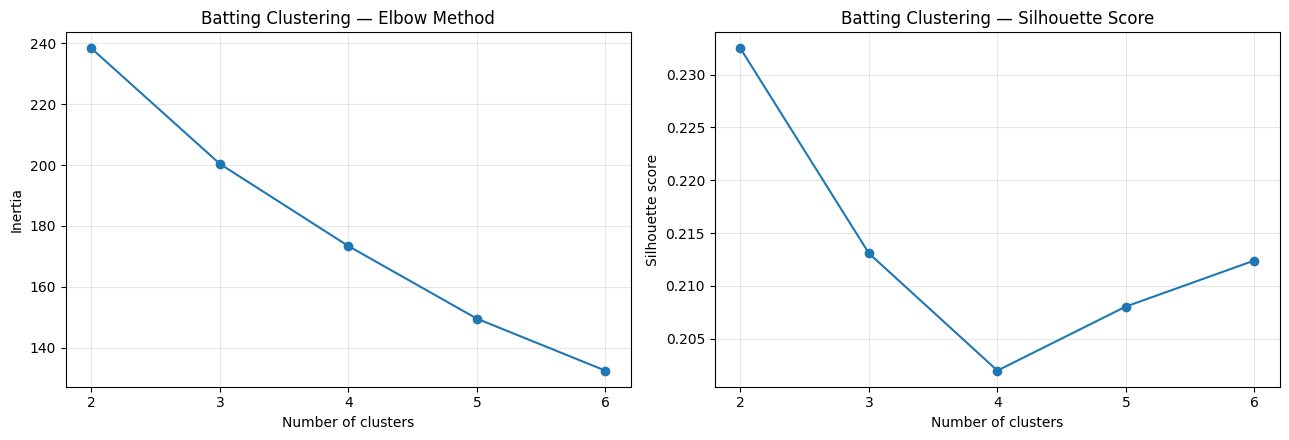

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(
    batting_cluster_evaluation["n_clusters"],
    batting_cluster_evaluation["inertia"],
    marker="o",
)
axes[0].set_title("Batting Clustering — Elbow Method")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(batting_cluster_evaluation["n_clusters"])
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    batting_cluster_evaluation["n_clusters"],
    batting_cluster_evaluation["silhouette_score"],
    marker="o",
)
axes[1].set_title("Batting Clustering — Silhouette Score")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Silhouette score")
axes[1].set_xticks(batting_cluster_evaluation["n_clusters"])
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
# Fit the selected batting clustering model.
BATTER_N_CLUSTERS = 2

batting_kmeans = KMeans(
    n_clusters=BATTER_N_CLUSTERS,
    random_state=42,
    n_init=20,
)

batting_features["batting_cluster"] = batting_kmeans.fit_predict(
    X_batting_scaled
)

# Inspect cluster sizes.
print("BATTING CLUSTER SIZES")
display(
    batting_features["batting_cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("batting_cluster")
    .reset_index(name="player_season_records")
)

# Profile clusters using interpretable, original-scale metrics.
batting_cluster_profiles = (
    batting_features
    .groupby("batting_cluster")
    .agg(
        player_season_records=("p_bat", "size"),
        distinct_players=("p_bat", "nunique"),
        mean_runs=("runs", "mean"),
        mean_balls_faced=("balls_faced", "mean"),
        mean_strike_rate=("strike_rate", "mean"),
        mean_dot_ball_pct=("dot_ball_pct", "mean"),
        mean_boundary_ball_pct=("boundary_ball_pct", "mean"),
        mean_powerplay_sr=("powerplay_strike_rate", "mean"),
        mean_middle_sr=("middle_strike_rate", "mean"),
        mean_death_sr=("death_strike_rate", "mean"),
    )
    .round(2)
)

print("BATTING CLUSTER PROFILES")
display(batting_cluster_profiles)

BATTING CLUSTER SIZES


,batting_cluster,player_season_records
0,0,30
1,1,37


BATTING CLUSTER PROFILES


,player_season_records,distinct_players,mean_runs,mean_balls_faced,mean_strike_rate,mean_dot_ball_pct,mean_boundary_ball_pct,mean_powerplay_sr,mean_middle_sr,mean_death_sr
batting_cluster,,,,,,,,,,
0,30,26,420.13,262.57,160.66,33.76,23.53,156.76,153.00,206.92
1,37,30,340.86,247.78,135.03,34.20,17.12,113.42,132.27,160.68


In [9]:
# Identify player-season combinations representing KKR batting records.
kkr_batter_seasons = (
    df_features.loc[
        df_features["team_bat"].eq("Kolkata Knight Riders"),
        ["p_bat", "year", "bat"],
    ]
    .drop_duplicates()
    .rename(columns={"bat": "kkr_batter_name"})
)

# Match KKR player-seasons to the clustering results.
kkr_batting_clusters = batting_features.merge(
    kkr_batter_seasons,
    on=["p_bat", "year"],
    how="inner",
    validate="one_to_one",
)

print("KKR PLAYER-SEASON CLUSTER ASSIGNMENTS")
display(
    kkr_batting_clusters[
        [
            "year",
            "kkr_batter_name",
            "runs",
            "balls_faced",
            "strike_rate",
            "powerplay_strike_rate",
            "middle_strike_rate",
            "death_strike_rate",
            "batting_cluster",
        ]
    ]
    .sort_values(["year", "batting_cluster", "runs"], ascending=[True, True, False])
    .reset_index(drop=True)
)

print("KKR CLUSTER DISTRIBUTION BY SEASON")
display(
    kkr_batting_clusters
    .groupby(["year", "batting_cluster"])
    .agg(
        player_season_records=("p_bat", "size"),
        distinct_players=("p_bat", "nunique"),
    )
    .reset_index()
)

KKR PLAYER-SEASON CLUSTER ASSIGNMENTS


,year,kkr_batter_name,runs,balls_faced,strike_rate,powerplay_strike_rate,middle_strike_rate,death_strike_rate,batting_cluster
0,2023,Nitish Rana,413,293,140.955631,132.394366,139.378238,172.413793,1
1,2023,Venkatesh Iyer,404,277,145.848375,130.275229,160.273973,127.272727,1
2,2024,Sunil Narine,488,270,180.740741,170.303030,190.322581,250.000000,0
3,2024,Venkatesh Iyer,370,233,158.798283,222.000000,142.142857,139.534884,0
4,2024,Shreyas Iyer,351,239,146.861925,69.230769,140.127389,201.785714,1


KKR CLUSTER DISTRIBUTION BY SEASON


,year,batting_cluster,player_season_records,distinct_players
0,2023,1,2,2
1,2024,0,2,2
2,2024,1,1,1


In [10]:
# Minimum season-level workload: 60 legal balls (10 overs).
MIN_BOWLING_BALLS = 60

bowling_features = player_season_bowling.loc[
    player_season_bowling["legal_balls"].ge(MIN_BOWLING_BALLS)
].copy()

bowling_cluster_columns = [
    "economy_rate",
    "bowling_dot_pct",
    "wickets_per_100_balls",
    "boundary_balls_per_100_legal_balls",
    "extras_per_20_overs",
]

print("Eligible player-season bowling records:", len(bowling_features))
print("Unique players:", bowling_features["p_bowl"].nunique())
print("Seasons represented:", sorted(bowling_features["year"].unique()))

print("\nMissing values in clustering features:")
display(
    bowling_features[bowling_cluster_columns]
    .isna()
    .sum()
    .rename("missing_count")
    .to_frame()
)

print("\nBowling feature sample:")
display(
    bowling_features[
        ["bowler_name", "year", "legal_balls", "wickets"]
        + bowling_cluster_columns
    ].head(10)
)

Eligible player-season bowling records: 164
Unique players: 111
Seasons represented: [np.int64(2023), np.int64(2024)]

Missing values in clustering features:


,missing_count
economy_rate,0
bowling_dot_pct,0
wickets_per_100_balls,0
boundary_balls_per_100_legal_balls,0
extras_per_20_overs,0



Bowling feature sample:


,bowler_name,year,legal_balls,wickets,economy_rate,bowling_dot_pct,wickets_per_100_balls,boundary_balls_per_100_legal_balls,extras_per_20_overs
0,Moeen Ali,2023,156,9,7.500000,34.615385,5.769231,12.820513,0.769231
2,Mohammad Nabi,2024,74,2,8.837838,24.324324,2.702703,16.216216,0.000000
3,Ravichandran Ashwin,2023,294,14,7.510204,29.931973,4.761905,11.564626,6.530612
4,Ravichandran Ashwin,2024,330,9,8.490909,26.363636,2.727273,13.030303,10.181818
5,Karn Sharma,2023,129,10,10.372093,28.682171,7.751938,22.480620,2.790698
6,Karn Sharma,2024,144,7,10.583333,27.083333,4.861111,24.305556,4.166667
7,Amit Mishra,2023,114,7,7.842105,26.315789,6.140351,14.035088,1.052632
9,Piyush Chawla,2023,366,22,8.114754,32.786885,6.010929,16.666667,1.639344
10,Piyush Chawla,2024,210,13,8.914286,30.952381,6.190476,16.190476,5.142857
12,Sunil Narine,2023,288,11,7.979167,29.166667,3.819444,13.888889,3.750000


In [12]:
X_bowling = bowling_features[bowling_cluster_columns].copy()

bowling_scaler = StandardScaler()
X_bowling_scaled = bowling_scaler.fit_transform(X_bowling)

bowling_cluster_results = []

for k in range(2, 6):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20,
    )

    labels = model.fit_predict(X_bowling_scaled)

    bowling_cluster_results.append(
        {
            "n_clusters": k,
            "inertia": model.inertia_,
            "silhouette_score": silhouette_score(
                X_bowling_scaled,
                labels,
            ),
            "smallest_cluster_size": pd.Series(labels).value_counts().min(),
        }
    )

bowling_cluster_evaluation = pd.DataFrame(bowling_cluster_results)

display(bowling_cluster_evaluation.round(3))

,n_clusters,inertia,silhouette_score,smallest_cluster_size
0,2,584.368,0.253,78
1,3,468.336,0.248,53
2,4,412.724,0.248,7
3,5,363.383,0.238,13


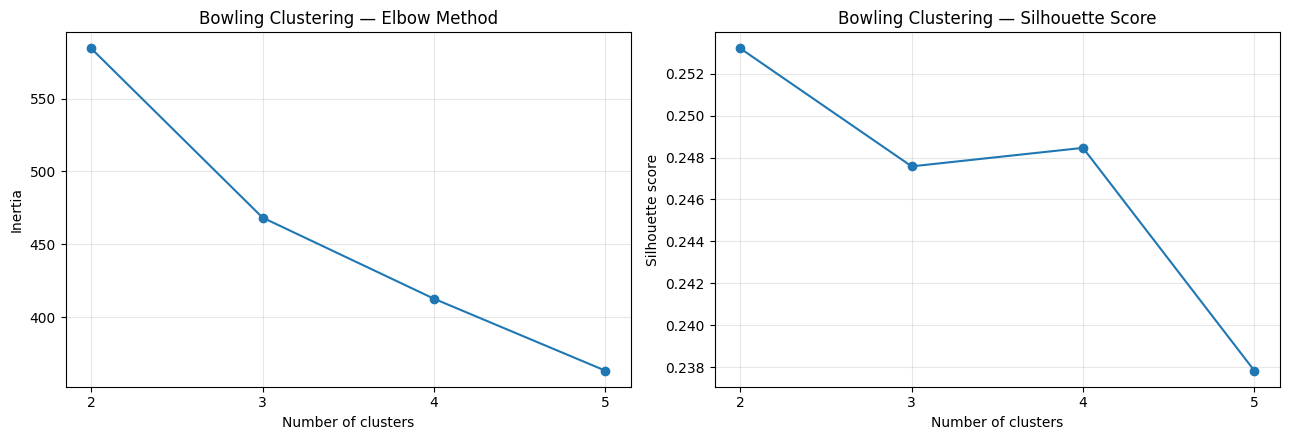

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(
    bowling_cluster_evaluation["n_clusters"],
    bowling_cluster_evaluation["inertia"],
    marker="o",
)
axes[0].set_title("Bowling Clustering — Elbow Method")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(bowling_cluster_evaluation["n_clusters"])
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    bowling_cluster_evaluation["n_clusters"],
    bowling_cluster_evaluation["silhouette_score"],
    marker="o",
)
axes[1].set_title("Bowling Clustering — Silhouette Score")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Silhouette score")
axes[1].set_xticks(bowling_cluster_evaluation["n_clusters"])
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
BOWLER_N_CLUSTERS = 2

bowling_kmeans = KMeans(
    n_clusters=BOWLER_N_CLUSTERS,
    random_state=42,
    n_init=20,
)

bowling_features["bowling_cluster"] = bowling_kmeans.fit_predict(
    X_bowling_scaled
)

print("BOWLING CLUSTER SIZES")
display(
    bowling_features["bowling_cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("bowling_cluster")
    .reset_index(name="player_season_records")
)

bowling_cluster_profiles = (
    bowling_features
    .groupby("bowling_cluster")
    .agg(
        player_season_records=("p_bowl", "size"),
        distinct_players=("p_bowl", "nunique"),
        mean_legal_balls=("legal_balls", "mean"),
        mean_wickets=("wickets", "mean"),
        mean_economy=("economy_rate", "mean"),
        mean_dot_pct=("bowling_dot_pct", "mean"),
        mean_wickets_per_100_balls=("wickets_per_100_balls", "mean"),
        mean_boundary_balls_per_100=(
            "boundary_balls_per_100_legal_balls", "mean"
        ),
        mean_extras_per_20_overs=("extras_per_20_overs", "mean"),
    )
    .round(2)
)

print("BOWLING CLUSTER PROFILES")
display(bowling_cluster_profiles)

BOWLING CLUSTER SIZES


,bowling_cluster,player_season_records
0,0,86
1,1,78


BOWLING CLUSTER PROFILES


,player_season_records,distinct_players,mean_legal_balls,mean_wickets,mean_economy,mean_dot_pct,mean_wickets_per_100_balls,mean_boundary_balls_per_100,mean_extras_per_20_overs
bowling_cluster,,,,,,,,,
0,86,64,207.05,10.86,8.24,34.40,5.25,16.67,4.60
1,78,61,164.99,8.50,10.27,32.81,4.93,24.81,8.71


In [15]:
# Identify KKR bowler-season combinations from the delivery-level data.
kkr_bowler_seasons = (
    df_features.loc[
        df_features["team_bowl"].eq("Kolkata Knight Riders"),
        ["p_bowl", "year", "bowl"],
    ]
    .drop_duplicates()
    .rename(columns={"bowl": "kkr_bowler_name"})
)

# Join the KKR records to the league-wide cluster assignments.
kkr_bowling_clusters = bowling_features.merge(
    kkr_bowler_seasons,
    on=["p_bowl", "year"],
    how="inner",
    validate="one_to_one",
)

print("KKR BOWLER-SEASON CLUSTER ASSIGNMENTS")
display(
    kkr_bowling_clusters[
        [
            "year",
            "kkr_bowler_name",
            "legal_balls",
            "wickets",
            "economy_rate",
            "bowling_dot_pct",
            "wickets_per_100_balls",
            "boundary_balls_per_100_legal_balls",
            "extras_per_20_overs",
            "bowling_cluster",
        ]
    ]
    .sort_values(
        ["year", "bowling_cluster", "wickets"],
        ascending=[True, True, False],
    )
    .reset_index(drop=True)
)

print("KKR BOWLING CLUSTER DISTRIBUTION BY SEASON")
display(
    kkr_bowling_clusters
    .groupby(["year", "bowling_cluster"])
    .agg(
        player_season_records=("p_bowl", "size"),
        distinct_players=("p_bowl", "nunique"),
    )
    .reset_index()
)

KKR BOWLER-SEASON CLUSTER ASSIGNMENTS


,year,kkr_bowler_name,legal_balls,wickets,economy_rate,bowling_dot_pct,wickets_per_100_balls,boundary_balls_per_100_legal_balls,extras_per_20_overs,bowling_cluster
0,2023,Varun Chakravarthy,316,20,8.145570,36.392405,6.329114,17.405063,4.556962,0
1,2023,Sunil Narine,288,11,7.979167,29.166667,3.819444,13.888889,3.750000,0
2,2023,Suyash Sharma,234,10,8.230769,34.188034,4.273504,17.094017,2.564103,0
3,2023,Harshit Rana,102,5,8.647059,43.137255,4.901961,23.529412,7.058824,0
4,2023,Andre Russell,91,7,11.340659,34.065934,7.692308,28.571429,10.549451,1
5,2023,Shardul Thakur,126,7,10.476190,25.396825,5.555556,25.396825,5.714286,1
6,2023,Vaibhav Arora,96,5,9.125000,31.250000,5.208333,19.791667,15.000000,1
7,2023,Umesh Yadav,114,1,9.947368,35.964912,0.877193,25.438596,2.105263,1
8,2024,Varun Chakravarthy,300,21,7.960000,40.333333,7.000000,16.333333,3.600000,0
9,2024,Harshit Rana,253,19,9.083004,36.758893,7.509881,20.553360,5.217391,0


KKR BOWLING CLUSTER DISTRIBUTION BY SEASON


,year,bowling_cluster,player_season_records,distinct_players
0,2023,0,4,4
1,2023,1,4,4
2,2024,0,3,3
3,2024,1,3,3


In [16]:
kkr_bowling_cluster_mix = pd.crosstab(
    kkr_bowling_clusters["year"],
    kkr_bowling_clusters["bowling_cluster"],
)

kkr_bowling_cluster_pct = (
    pd.crosstab(
        kkr_bowling_clusters["year"],
        kkr_bowling_clusters["bowling_cluster"],
        normalize="index",
    )
    .mul(100)
    .round(1)
)

print("KKR BOWLER-SEASON COUNTS")
display(kkr_bowling_cluster_mix)

print("KKR BOWLER-SEASON DISTRIBUTION (%)")
display(kkr_bowling_cluster_pct)

KKR BOWLER-SEASON COUNTS


bowling_cluster,0,1
year,,
2023,4,4
2024,3,3


KKR BOWLER-SEASON DISTRIBUTION (%)


bowling_cluster,0,1
year,,
2023,50.0,50.0
2024,50.0,50.0


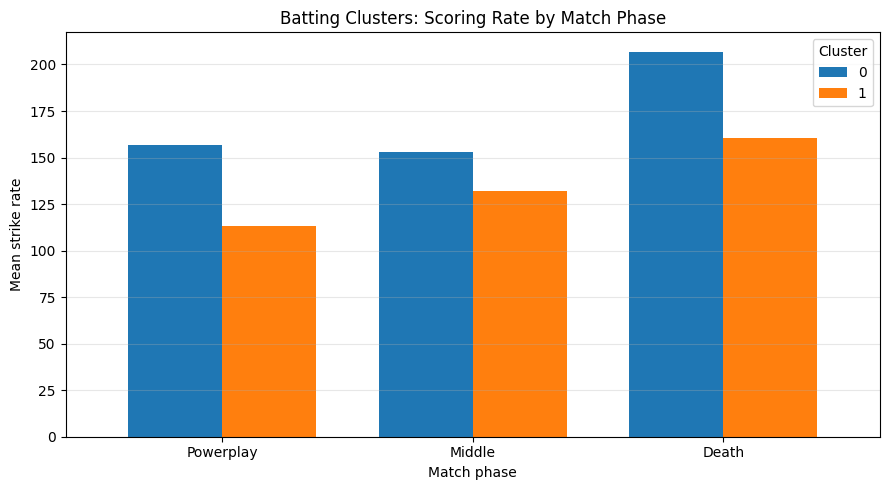

In [17]:
batting_plot_data = (
    batting_cluster_profiles[
        ["mean_powerplay_sr", "mean_middle_sr", "mean_death_sr"]
    ]
    .rename(
        columns={
            "mean_powerplay_sr": "Powerplay",
            "mean_middle_sr": "Middle",
            "mean_death_sr": "Death",
        }
    )
)

ax = batting_plot_data.T.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.75,
)

ax.set_title("Batting Clusters: Scoring Rate by Match Phase")
ax.set_xlabel("Match phase")
ax.set_ylabel("Mean strike rate")
ax.legend(title="Cluster")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

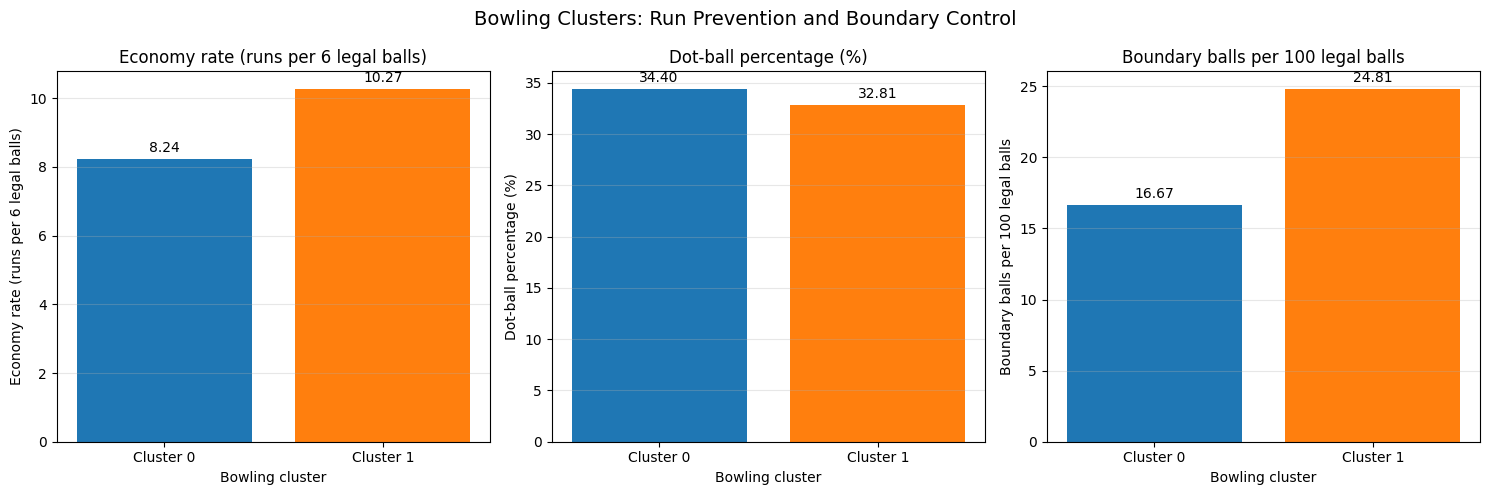

<Figure size 640x480 with 0 Axes>

In [21]:
# Plot bowling cluster metrics in their original units.
bowling_control_metrics = [
    ("mean_economy", "Economy rate (runs per 6 legal balls)"),
    ("mean_dot_pct", "Dot-ball percentage (%)"),
    ("mean_boundary_balls_per_100", "Boundary balls per 100 legal balls"),
]

# Reuse the default Matplotlib colour cycle used in the batting chart.
cluster_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (metric, title) in zip(axes, bowling_control_metrics):
    values = bowling_cluster_profiles[metric]

    bars = ax.bar(
        values.index.astype(str),
        values.values,
        color=[
            cluster_colors[int(cluster)]
            for cluster in values.index
        ],
    )

    ax.set_title(title)
    ax.set_xlabel("Bowling cluster")
    ax.set_ylabel(title)
    ax.set_xticks(range(len(values)))
    ax.set_xticklabels(
        [f"Cluster {cluster}" for cluster in values.index]
    )
    ax.grid(axis="y", alpha=0.3)
    ax.bar_label(bars, fmt="%.2f", padding=3)

fig.suptitle(
    "Bowling Clusters: Run Prevention and Boundary Control",
    fontsize=14,
)

plt.tight_layout()
plt.show()

fig.suptitle(
    "Bowling Clusters: Run Prevention and Boundary Control",
    fontsize=14,
)

plt.tight_layout()
plt.show()

## 6. Interpretation of Player Performance Clusters

### 6.1 Batting Clusters

The batting analysis identified two broad player-season profiles using K-Means clustering. The model uses standardised overall dot-ball percentage, boundary-ball percentage, and strike rates across the Powerplay, Middle Overs, and Death Overs.

**Cluster 0 — Higher-tempo, boundary-oriented batting**
- Higher average overall strike rate and boundary-ball percentage.
- Higher average strike rates across all three match phases.
- Average overall strike rate: approximately 160.66.
- Average boundary-ball percentage: approximately 23.53%.

**Cluster 1 — Lower-tempo batting**
- Lower average overall strike rate and boundary-ball percentage.
- Lower average strike rates across all three match phases.
- Average overall strike rate: approximately 135.03.
- Average boundary-ball percentage: approximately 17.12%.

The average dot-ball percentages are similar across the two clusters, suggesting that the distinction is driven more by scoring tempo and boundary frequency than by dot-ball avoidance alone.

The silhouette score for the selected two-cluster solution was approximately 0.232. This indicates relatively weak separation between clusters, so the profiles should be interpreted as broad tendencies rather than sharply distinct player types.

Only 67 player-season records met the batting eligibility criteria. Players needed at least 60 balls faced overall and at least 12 balls faced in each of the three match phases. This excludes some phase specialists and limits the population represented by the clusters.

### 6.2 Bowling Clusters

The bowling analysis identified two broad player-season profiles using standardised economy rate, bowling dot-ball percentage, wickets per 100 legal balls, boundary balls per 100 legal balls, and extras per 20 overs.

**Cluster 0 — More controlled bowling**
- Average economy rate: 8.24 runs per six legal balls.
- Average dot-ball percentage: 34.40%.
- Average wickets per 100 legal balls: 5.25.
- Average boundary balls per 100 legal balls: 16.67.
- Average extras per 20 overs: 4.60.

**Cluster 1 — Higher-concession bowling**
- Average economy rate: 10.27 runs per six legal balls.
- Average dot-ball percentage: 32.81%.
- Average wickets per 100 legal balls: 4.93.
- Average boundary balls per 100 legal balls: 24.81.
- Average extras per 20 overs: 8.71.

Cluster 0 exhibits stronger run-control indicators: lower economy, fewer boundary balls, and fewer extras. Its average wicket rate is also modestly higher. These are cluster-level averages, not guarantees of individual performance.

The silhouette score for the selected two-cluster solution was approximately 0.253. As with batting, the separation is modest, and the clusters should be treated as descriptive profiles rather than definitive classifications.

The bowling analysis included 164 eligible player-season records, with a minimum of 60 legal balls bowled per player-season.

### 6.3 KKR Player Profiles Across Seasons

Among the KKR batting records that met the clustering eligibility criteria, the distribution changed between seasons:
- **2023:** Two qualifying player-season records belonged to Cluster 1.
- **2024:** Two qualifying records belonged to Cluster 0 and one to Cluster 1.

The qualifying batting sample is small and should not be interpreted as a complete assessment of KKR's batting unit.

For bowling, the eligible KKR player-season records were evenly distributed across the two clusters in both seasons:
- **2023:** Four records in each cluster.
- **2024:** Three records in each cluster.

Varun Chakravarthy and Sunil Narine remained in Cluster 0 across the two seasons. Andre Russell remained in Cluster 1, although his individual wicket rate improved and his economy rate declined in 2024.

These examples illustrate why cluster labels must be interpreted alongside the underlying metrics. A player can improve substantially without changing clusters, and a cluster assignment does not by itself establish a player's value to the team.

### 6.4 Limitations and Responsible Interpretation

1. **Limited time coverage:** The analysis covers only the 2023 and 2024 IPL seasons.
2. **Repeated player observations:** A player appearing in both seasons contributes two player-season records. These observations are not statistically independent.
3. **Role differences:** Batting position, match phase, bowling role, workload, opposition quality, and match situation can affect performance.
4. **Eligibility filters:** Minimum-ball thresholds improve the reliability of rate statistics but exclude low-workload players and some specialists.
5. **Modest cluster separation:** The silhouette scores indicate that the clusters are broad descriptive groupings, not naturally separated categories.
6. **Data-quality limitations:** The previously identified inconsistencies in the source `bowlruns` field may affect bowling-related metrics derived from it.
7. **No predictive or causal claims:** The clustering does not predict future performance, establish causality, or independently determine player selection and recruitment decisions.

### 6.5 Conclusion

Player performance clustering provides a compact way to explore broad differences in batting tempo and bowling control. It complements the earlier descriptive analysis and scouting work by grouping player-season observations with similar statistical profiles.

However, the clusters should be used as an exploratory decision-support tool. Any player comparison or tactical recommendation should also consider role, workload, match context, sample size, and the underlying performance metrics.